# Lives in space: birth → death places

Exploratory analysis of `birth_death_places_geo.csv` to prepare an **arc + map visualisation**
(one arc per person, from place of birth to place of death).

Questions: what is in the file, how many persons can actually be drawn as an arc, and how trustworthy are the coordinates?
The decisions taken here are implemented in [`build_map_json.py`](../src/data/build_map_json.py), which writes the JSON for the visualisation.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd().parent / "src" / "data"))
import build_map_json as bm  # shared helpers: haversine, year parsing, suspect-place check

pl.Config.set_fmt_str_lengths(60)
pl.Config.set_tbl_rows(20)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

geo = bm.load_geo()
places = bm.load_places()
geo.head(3)

place_id,role,ark,person_label,lat,long
i64,i64,str,str,f64,f64
7090,1,"""https://ark.burgerbib.ch/ark:36599/00pgbn81p1g""","""Küpfer, Anna Magdalena (1851-1919)""",46.875225,7.7974921
8767,1,"""https://ark.burgerbib.ch/ark:36599/01cgvjrp45s""","""Pfenninger, Heinrich (1749-1815)""",47.374449,8.5410422
6775,2,"""https://ark.burgerbib.ch/ark:36599/01fx8x0q3g2""","""Zimmer, Johann Heinrich Ehrenfried (1774-1851)""",47.140208,7.2439029


## 1. Shape of the file
One row = one person × place × role (1 = birth, 2 = death).

In [2]:
print(f"rows: {geo.height}  persons: {geo['ark'].n_unique()}  places: {geo['place_id'].n_unique()}")
print("nulls:", geo.null_count().row(0))

# which role combinations does a person have? (e.g. '12' = one birth + one death place)
combos = (geo.group_by("ark").agg(pl.col("role").sort().cast(pl.String).str.join("").alias("roles"))
             ["roles"].value_counts().sort("count", descending=True))
combos

rows: 3417  persons: 2296  places: 698
nulls: (0, 0, 0, 0, 0, 0)


roles,count
str,u32
"""12""",1110
"""1""",635
"""2""",544
"""11""",4
"""122""",1
"""112""",1
"""1122""",1


**Take-away:** only ~48% of persons (1,110 + a few multi-place cases) have *both* a birth and a death place.
The rest have just one, so they can be shown as points but not as arcs. A handful have several candidate places (`11`, `122`, `112`, `1122`).

In [3]:
persons = geo.group_by("ark").agg(
    (pl.col("role") == 1).any().alias("has_birth"), (pl.col("role") == 2).any().alias("has_death")
)
persons.group_by("has_birth", "has_death").len().sort("len", descending=True)

has_birth,has_death,len
bool,bool,u32
true,true,1113
true,false,639
false,true,544


### Coverage against the full person–place relations
How many birth/death links of the archive are in this file?

In [4]:
d = bm.HERE
links = (pl.read_parquet(d / "persons_descriptors_places_descriptors.parquet")
           .filter(pl.col("role").is_in([1, 2]))
           .join(pl.read_parquet(bm.PLACES_PATH).select(pl.col("id").alias("id_place_descriptor"), "id_name", "label"), on="id_place_descriptor")
           .with_columns(pl.struct("id_name", "label").map_elements(lambda s: bm.place_country(s["id_name"], s["label"]), return_dtype=pl.String).eq("Schweiz (CH)").alias("swiss"))
           .with_columns(pl.col("id_place_descriptor").is_in(geo["place_id"].unique().to_list()).alias("in_file")))
print(f"archive: {links.height} birth/death links, {links['id_person_descriptor'].n_unique()} persons;  file: {geo.height} rows, {geo['ark'].n_unique()} persons")
links.group_by("swiss", "in_file").len().sort("swiss", "in_file")

archive: 4264 birth/death links, 2742 persons;  file: 3417 rows, 2296 persons


swiss,in_file,len
bool,bool,u32
false,false,833
false,true,542
true,false,11
true,true,2878


**Take-away:** the file covers almost every *Swiss* place (2,878 of 2,889 links) and, since the latest update, 542 of 1,375 foreign links (France, Italy, Great Britain, USA, …).
About 833 birth/death links, roughly a fifth of the archive's, still sit on non-Swiss descriptors without coordinates,
so the most interesting long-distance arcs are still partly missing.

## 2. Places: a few hubs dominate

top 5 places = 42% of all rows; 419 of 698 places appear only once


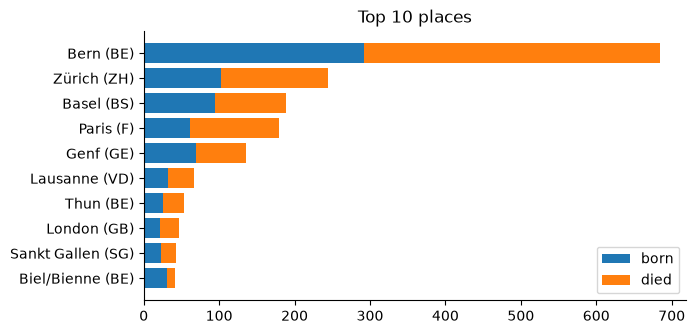

In [5]:
by_place = (geo.group_by("place_id").agg((pl.col("role") == 1).sum().alias("births"), (pl.col("role") == 2).sum().alias("deaths"))
              .with_columns((pl.col("births") + pl.col("deaths")).alias("total"))
              .join(places.select("place_id", "label", "country"), on="place_id")
              .sort("total", descending=True))
top = by_place.head(10)
print(f"top 5 places = {by_place['total'].head(5).sum() / geo.height:.0%} of all rows; "
      f"{(by_place['total'] == 1).sum()} of {by_place.height} places appear only once")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(top["label"][::-1], top["births"][::-1], label="born")
ax.barh(top["label"][::-1], top["deaths"][::-1], left=top["births"][::-1], label="died")
ax.set_title("Top 10 places"); ax.legend(); plt.show()

**Take-away:** Bern alone accounts for ~20% of rows and the top 5 places for 42%, while 419 of 698 places appear only once.
Arcs will converge on a few hubs, so aggregated flows (origin → destination with a count) are worth shipping next to the per-person arcs.

## 3. Geocoding quality
Two checks that need no reference geometry:
1. **Swiss descriptors**: a place whose hierarchy is `Orte\Sch\Schweiz (CH)\…` but lies outside a bounding box around Switzerland is a geocoding error (OSM matched a homonym). This is what `build_map_json.py` flags as `suspect`.
2. **Foreign descriptors**: compare the country code of the OSM match (`osm/<place_id>.json`) with the country in the descriptor hierarchy.

country of descriptor:
shape: (6, 2)
┌──────────────────────┬───────┐
│ country              ┆ count │
│ ---                  ┆ ---   │
│ str                  ┆ u32   │
╞══════════════════════╪═══════╡
│ Schweiz (CH)         ┆ 550   │
│ Frankreich (F)       ┆ 70    │
│ Italien (I)          ┆ 39    │
│ Grossbritannien (GB) ┆ 18    │
│ USA (USA)            ┆ 12    │
│ Griechenland (GRC)   ┆ 2     │
└──────────────────────┴───────┘
check 1: 0 of 698 places are outside Switzerland although Swiss by descriptor


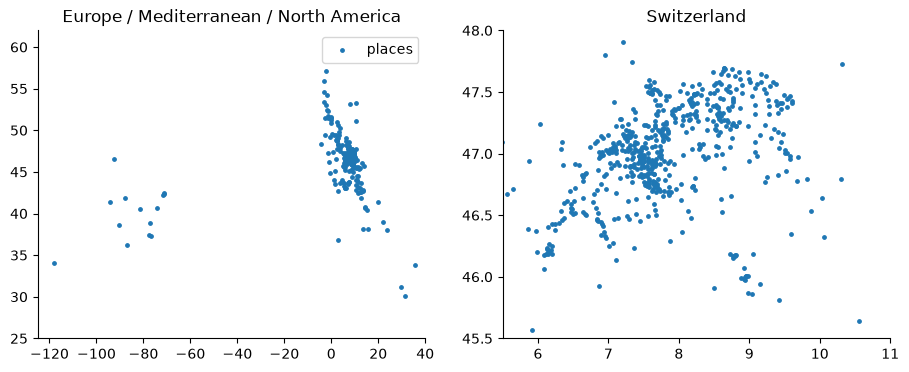

In [6]:
print("country of descriptor:"); print(places["country"].value_counts().sort("count", descending=True).head(6))
suspect = places.filter("suspect")
print(f"check 1: {suspect.height} of {places.height} places are outside Switzerland although Swiss by descriptor")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
for ax, (xl, yl) in zip((a1, a2), (((-125, 40), (25, 62)), ((5.5, 11), (45.5, 48)))):
    ax.scatter(places["lon"], places["lat"], s=6, c="tab:blue", label="places")
    if suspect.height:
        ax.scatter(suspect["lon"], suspect["lat"], s=14, c="tab:red", label="suspect")
    ax.set_xlim(xl); ax.set_ylim(yl)
a1.set_title("Europe / Mediterranean / North America"); a2.set_title("Switzerland"); a1.legend(); plt.show()

In [7]:
import json

# check 2: descriptor country -> expected ISO 3166 alpha-2 code of the OSM match (only countries with an unambiguous mapping)
expected = {"Frankreich (F)": "fr", "Italien (I)": "it", "Grossbritannien (GB)": "gb", "Deutschland (D)": "de", "Ungarn (H)": "hu"}

def osm_country(pid):
    try:
        return json.loads((bm.HERE / "osm" / f"{pid}.json").read_text())[0]["address"].get("country_code")
    except Exception:
        return None

foreign = (places.filter(pl.col("country").is_in(list(expected)))
           .with_columns(pl.col("place_id").map_elements(osm_country, return_dtype=pl.String).alias("osm_cc"),
                         pl.col("country").replace(expected).alias("expected_cc"))
           .filter(pl.col("osm_cc") != pl.col("expected_cc")))
print(f"check 2: {foreign.height} of {places.filter(pl.col('country').is_in(list(expected))).height} places have an OSM country other than the descriptor's")
foreign.select("place_id", "id_name", "osm_cc", "lat", "lon")

check 2: 8 of 129 places have an OSM country other than the descriptor's


place_id,id_name,osm_cc,lat,lon
i64,str,str,f64,f64
1028,"""Ofen (H) (Orte\U\Ungarn (H))""","""de""",53.169261,8.1498969
6906,"""Carlton (GB) (Orte\G\Grossbritannien (GB))""","""us""",46.579993,-92.720633
6948,"""Chesterfield (GB) (Orte\G\Grossbritannien (GB))""","""us""",37.385998,-77.578509
7058,"""Dornach (F) (Orte\F\Frankreich (F))""","""ch""",47.48061,7.6176609
7315,"""Guernsey (GB) (Orte\G\Grossbritannien (GB))""","""gg""",49.462291,-2.581202
8491,"""Tirano (I) (Orte\I\Italien (I))""","""al""",41.328378,19.817982
8727,"""Worcester (GB) (Orte\G\Grossbritannien (GB))""","""us""",42.262562,-71.801888
8740,"""Yoré (F) (Orte\F\Frankreich (F))""","""gb""",54.256375,-1.656951


**Take-away:** the 48 wrongly placed Swiss places from [issue #2](https://github.com/burgerbibliothek/glamhack26/issues/2) are fixed (check 1 finds none).
Check 2 finds a few new problems among the foreign places that were geocoded since, for example *Worcester (GB)* → Massachusetts, *Carlton (GB)* → Minnesota, *Dornach (F)* → Solothurn, *Tirano (I)* → Tirana, *Ofen (H)* → Lower Saxony
(*Guernsey* is listed only because OSM uses its own country code). Only 2 arcs touch them so far.
The US places (12) cannot be checked this way, as their OSM matches carry no country code, and a wrong location *inside* Switzerland (wrong canton) is still undetected.

## 4. Arcs: distance, same-place and multiple candidates

In [8]:
data = bm.build(keep_suspect=True)           # keep everything here to quantify it
arcs = pl.DataFrame(data["arcs"])
print({k: v for k, v in data["meta"].items() if k.startswith(("persons", "skipped", "n_arcs"))})
print(f"ambiguous persons (several birth/death places): {arcs.filter('ambiguous')['ark'].n_unique()}")

{'n_arcs': 694, 'persons': 2296, 'persons_with_arc_candidate': 1113, 'skipped_suspect': 0, 'skipped_same_place': 424}
ambiguous persons (several birth/death places): 3


shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 694.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 232.567723 │
│ std        ┆ 874.851933 │
│ min        ┆ 1.2        │
│ 25%        ┆ 22.0       │
│ 50%        ┆ 61.9       │
│ 75%        ┆ 128.1      │
│ max        ┆ 9507.1     │
└────────────┴────────────┘


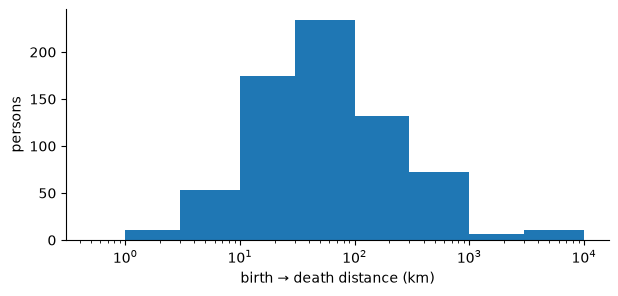

name,birth_year,death_year,source,target,distance_km
str,i64,i64,i64,i64,f64
"""Keller, Adolf (1872-1963)""",1872,1963,8194,7683,9507.1
"""Schaffter, Albert (1823-1897)""",1823,1897,6752,347661,7451.2
"""Gressmann, Hugo (1877-1927)""",1877,1927,913,6950,7002.4
"""Reidenbach, Wilhelm (1794-1874)""",1794,1874,6802,546867,6798.9
"""Graffenried, Anton Tscharner von (1722-1795)""",1722,1795,8701,7703,6603.5
"""Hügli, Alice (1901-1994)""",1901,1994,6752,8655,6598.9
"""Eugster, Howard (1861-1932)""",1861,1932,7926,8366,6382.7
"""Eugster, Arthur (1863-1922)""",1863,1922,7926,8366,6382.7
"""Strauss, Carl (1873-1957)""",1873,1957,6813,7570,6094.6


In [9]:
clean = pl.DataFrame(bm.build(keep_suspect=False)["arcs"])
print(clean["distance_km"].describe())

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(clean["distance_km"], bins=[0.5, 1, 3, 10, 30, 100, 300, 1000, 3000, 10000], color="tab:blue")
ax.set_xscale("log"); ax.set_xlabel("birth → death distance (km)"); ax.set_ylabel("persons"); plt.show()

clean.sort("distance_km", descending=True).select("name", "birth_year", "death_year", "source", "target", "distance_km").head(10)

**Take-away:** of 1,113 persons with both places, ~420 were born and died in the same place (distance < 0.5 km) and give no visible arc.
694 arcs remain. The median is 62 km, 221 arcs exceed 100 km, 89 exceed 300 km and 17 exceed 1,000 km (the longest, almost 9,500 km, goes to the other side of the world).
553 of the 694 arcs (80%) are Swiss-internal.
The distribution is heavily skewed, so use a log or capped scale for width/colour in the viewer.

## 5. Time: can we add a time slider?
Years are parsed from the label, e.g. `(1679-1767)`. Partial dates such as `19??`, `belegt …` or `?` give no year.

birth year known: 98%, death year known: 99%


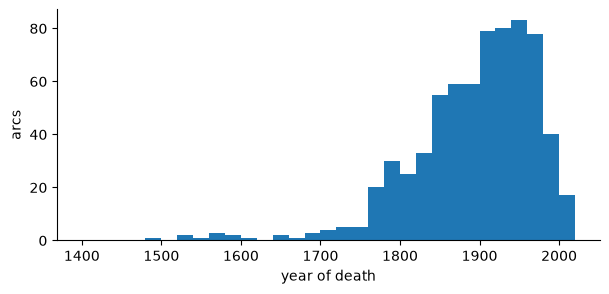

In [10]:
n = clean.height
print(f"birth year known: {clean['birth_year'].is_not_null().sum() / n:.0%}, death year known: {clean['death_year'].is_not_null().sum() / n:.0%}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(clean["death_year"].drop_nulls(), bins=range(1400, 2040, 20)); ax.set_xlabel("year of death"); ax.set_ylabel("arcs"); plt.show()

**Take-away:** 98% of arcs have a birth year and 99% a death year. The median death year is 1908 (10th percentile 1795, 90th 1974; only 16 arcs before 1700),
so a time slider or colour by period is feasible but will mostly cover the 19th–20th century.

## 6. Decisions implemented in `build_map_json.py`
| Topic | Decision |
|---|---|
| Arc definition | one arc per person = birth place → death place; persons with several candidates get one arc per pair, flagged `ambiguous` |
| Persons with one place only | no arc; they appear only in the `places` point layer (`births` / `deaths` counts) |
| Same place | arcs < 0.5 km dropped (counted in `meta.skipped_same_place`) |
| Wrong coordinates | Swiss descriptors outside the Swiss bounding box → `suspect`, excluded from places/arcs (`--keep-suspect` to keep); none left in the current data. The foreign-country check (section 3) is a notebook diagnostic only |
| Output | `places`, `arcs` (deck.gl-friendly `from`/`to` = `[lon, lat]`), aggregated `flows`, and `meta` |
| Years | parsed from the label, `null` if unknown |

Run: `python src/data/build_map_json.py` → `src/data/map_data.json`

In [11]:
out = bm.DEFAULT_OUT
import json
out.write_text(json.dumps(bm.build(), ensure_ascii=False, separators=(",", ":")), encoding="utf-8")
print(out, f"{out.stat().st_size / 1024:.0f} kB")

/Users/mromanello/Documents/GLAMHack2026/GLAMHACK26-BurgerBib-LivesInSpace/data/src/data/map_data.json 291 kB
